# 05 - The IRF forward operator

The instrument does not observe the true cube $\mu_t$ from the previous notebooks.  It
observes

$$\lambda_r = \sum_t P(r\,|\,t)\,\mu_t + \mathrm{CCR}_r ,$$

where $P(r|t)$ is the probability that an event in true bin $t$ is *reconstructed* in bin $r$.
`IRFForwardConv` implements this as a separable, count-conserving convolution:

* **Padded true grid.** $\mu$ is evaluated on `geom.padded(op.pads)`, the analysis grid extended
  by the kernel half-width, so events from just outside the window can migrate in.  Output
  is the analysis grid ("valid" convolution).
* **Bin-integrated kernels.** `bin_prob_kernel` gives $P(\text{reco bin} = \text{true bin} + d)$ for a
  Gaussian smear and a true position uniform within its bin (box ⊗ Gaussian ⊗ box, closed form);
  every row sums to one.  The energy kernel lives in $\log_{10}E$ (resolution in **dex**), the
  spatial kernel in degrees and may depend on true energy.
* **Log-space interface.** Inputs and outputs are log counts; both passes run in linear space after an
  exp-shift (per true-energy plane, then per pixel), so nothing is lost until ~87 nats below the
  local maximum in float32.

The CCR background is a reconstructed-space quantity and is added **after** the operator.

In [1]:
import os, math, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Apple MPS: run the few unsupported ops on the CPU
import numpy as np
import torch
import matplotlib.pyplot as plt
from astropy import units as u

FAST = os.environ.get("GAMMABAYES_DOCS_FAST", "0") == "1"
# device: GAMMABAYES_DOCS_DEVICE=cpu|cuda|mps, else CUDA > Apple MPS > CPU.  MPS has no float64, so it runs in float32.
device = os.environ.get("GAMMABAYES_DOCS_DEVICE") or ("cuda" if torch.cuda.is_available()
                                                      else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_default_dtype(torch.float32 if device == "mps" else torch.float64)   # float64 where available: exactness over speed
torch.set_default_device(device)                # GammaBayes objects are created on the default device
print(f"torch {torch.__version__} on {device} ({torch.get_default_dtype()}), FAST={FAST}")

from gammabayes import GammaBinning, GammaLogExposure
from gammabayes.response_functions import IRFExtractor
from gammabayes.utils import IRFForwardConv, bin_prob_kernel, make_forward_irf_kernels
from gammabayes.priors import TwoCompFluxPrior
from gammabayes.priors.spectral_components import PowerLaw
from gammabayes.priors.spatial_components import PointSpatial_PriorComp
from gammabayes.dark_matter import Einasto_Profile, CustomDMRatiosModel
npy = lambda t: t.detach().cpu().numpy()

geom = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100., lon_res=10, lon_min=-3., lon_max=3., lat_res=10, lat_min=-3., lat_max=3.)
pointing = torch.tensor([0., 0.])
irfs = IRFExtractor(zenith_angle=20, hemisphere="South", prod_vers=5, pointing_dir=pointing, irf_time_seconds=180000)
E = geom.energy_axis
bwE = float(torch.log10(geom.energy_edges[1]) - torch.log10(geom.energy_edges[0]))     # dex
bwL = float(geom.lon_edges[1] - geom.lon_edges[0])
bwB = float(geom.lat_edges[1] - geom.lat_edges[0])
print(f"bin widths: {bwE:.3f} dex, {bwL:.2f} deg, {bwB:.2f} deg")

torch 2.15.0 on mps (torch.float32), FAST=False


/Volumes/Extreme SSD/GammaBayes/.gb_venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


bin widths: 0.100 dex, 0.10 deg, 0.10 deg


[wall time: 3.2 s]


## Building the operator

`make_forward_irf_kernels(bwE, bwL, bwB, log10E_std, lon_std, lat_std, clearance)` returns the
energy kernel `(K_d,)` and the spatial kernel `(K_h, K_w)` -- or `(E_true, K_h, K_w)` if the PSF
width is an `(E_true,)` tensor.  `IRFForwardConv` stores the flipped kernels (torch convolutions
are cross-correlations), the padding `pads = (K_d//2, K_h//2, K_w//2)` and chunks the batch axis
with `max_batch`.

In [2]:
kE, kS = make_forward_irf_kernels(bwE, bwL, bwB, log10E_std=0.09, lon_std=0.08, lat_std=0.08, clearance=4.0)
op = IRFForwardConv(kE, kS)
print("kernel size:", op.kernel_size, " pads:", op.pads)
tg = geom.padded(op.pads)                                   # the true-space geometry
print("reco grid:", geom.shape, " true grid:", tg.shape, " op.out_shape(true) ==", op.out_shape(tg.shape))
tlogexp = GammaLogExposure(binning_geometry=tg, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr)

kernel size: (9, 9, 9)  pads: (4, 4, 4)
reco grid: (30, 60, 60)  true grid: (38, 68, 68)  op.out_shape(true) == (30, 60, 60)


[wall time: 27 ms]


## A true-space model and its reconstructed image

Everything gamma-ray is evaluated on the **true** geometry `tg` with the **true** exposure.

In [3]:
gc = TwoCompFluxPrior(spectral_comp=PowerLaw(index=2.3, phi0=2.5e-12), spatial_comp=PointSpatial_PriorComp(),
                      binning_geometry=tg, log_exposure_map=tlogexp, name="GC")
dm = CustomDMRatiosModel(binning_geometry=tg, channels=["W+W-"], spatial_profile=Einasto_Profile, irf_loglike=irfs, log_exposure_map=tlogexp, name="DM")
log_gc = gc.eval_log_on_geom(spectral_params={"index": 2.3}, spatial_params={"pos_lon": 0., "pos_lat": 0.})
log_dm = dm.eval_log_on_geom(spectral_params={"mass": 1.0, "sigmav": 1e-25, "ratios": {"W+W-": 1.}}, spatial_params={"alpha": 0.17})
log_true = torch.logaddexp(log_gc, log_dm)                   # (E_t, lon_t, lat_t)

t0 = time.time()
log_reco = op(log_true)
dt = time.time() - t0
pE, pL, pB = op.pads
true_all = float(torch.exp(log_true).sum())
true_window = float(torch.exp(log_true[pE:-pE, pL:-pL, pB:-pB]).sum())
reco = float(torch.exp(log_reco).sum())
print(f"operator call: {dt*1e3:.0f} ms   output {tuple(log_reco.shape)}")
print(f"true counts: all {true_all:.6g}, inside the window {true_window:.6g};  reconstructed: {reco:.6g}  (ratio to window {reco/true_window:.4f})")

operator call: 167 ms   output (30, 60, 60)
true counts: all 842814, inside the window 517080;  reconstructed: 521047  (ratio to window 1.0077)


[wall time: 1.2 s]


The reconstructed total differs from the true counts in the window only by the net migration
across the window boundary (events from the padding that land inside minus events that leave).
The figure shows the point source before and after the PSF, and the summed spectrum before and
after energy dispersion.

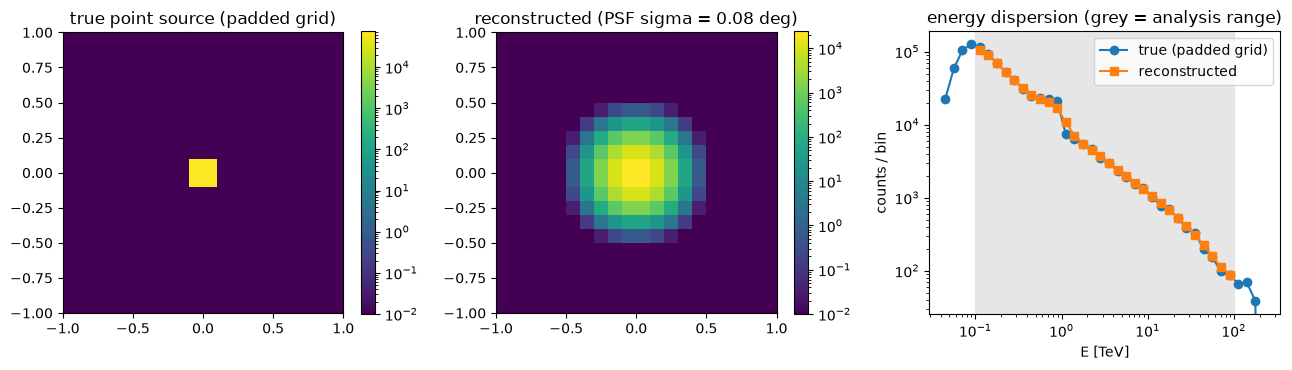

[wall time: 641 ms]


In [4]:
k = int(torch.argmin((E - 1.).abs()))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
pcm = ax[0].pcolormesh(npy(tg.lon_axis), npy(tg.lat_axis), npy(torch.exp(log_gc).sum(0)).T, shading="auto", norm="log", vmin=1e-2)
ax[0].set(title="true point source (padded grid)", aspect="equal", xlim=(-1, 1), ylim=(-1, 1))
plt.colorbar(pcm, ax=ax[0])
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), npy(torch.exp(op(log_gc)).sum(0)).T, shading="auto", norm="log", vmin=1e-2)
ax[1].set(title="reconstructed (PSF sigma = 0.08 deg)", aspect="equal", xlim=(-1, 1), ylim=(-1, 1))
plt.colorbar(pcm, ax=ax[1])
ax[2].loglog(npy(tg.energy_axis), npy(torch.exp(log_true).sum((1, 2))), "o-", label="true (padded grid)")
ax[2].loglog(npy(E), npy(torch.exp(log_reco).sum((1, 2))), "s-", label="reconstructed")
ax[2].axvspan(float(geom.energy_edges[0]), float(geom.energy_edges[-1]), color="0.9", zorder=-1)
ax[2].set(xlabel="E [TeV]", ylabel="counts / bin", title="energy dispersion (grey = analysis range)")
ax[2].legend()
plt.tight_layout()

## Energy-dependent PSF

The CTAO PSF shrinks from ~0.15° at 0.1 TeV to ~0.02° at 100 TeV.  Pass the width per **true**
energy bin: the spatial pass then runs with one kernel per true-energy plane *before* the energy
dispersion, which is the exact order for $P(r_E, r_x | t_E, t_x) = P_E(r_E|t_E)\,P_x(r_x - t_x | t_E)$.
Because the widths are needed on the padded energy axis, first pad in energy only, measure the
PSF there, then build the kernels.

per-energy kernel: (9, 13, 13)  pads: (4, 6, 6)  true grid: (38, 72, 72)
PSF sigma: 0.137 deg at 0.045 TeV -> 0.016 deg at 224 TeV


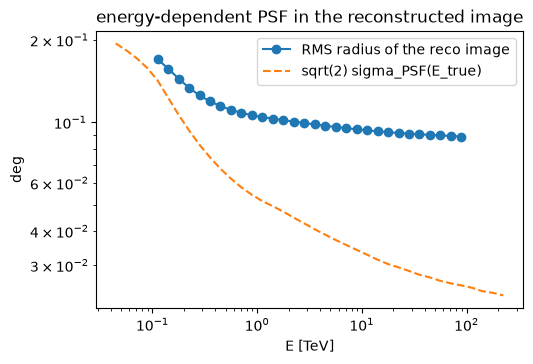

[wall time: 223 ms]


In [5]:
nE = max(1, math.ceil(4.0 * 0.09 / bwE))                              # same rule as bin_prob_kernel
g0 = geom.padded((nE, 0, 0))
sigma_t = irfs.psf_sigma_vs_energy(g0, fraction=0.68, weighting="aeff", pointing_dir=pointing, pixel_floor=False)   # (E_t,)
kE2, kS2 = make_forward_irf_kernels(bwE, bwL, bwB, log10E_std=0.09, lon_std=sigma_t, lat_std=sigma_t, clearance=4.0)
op2 = IRFForwardConv(kE2, kS2)
assert op2.pads[0] == nE
tg2 = geom.padded(op2.pads)
print("per-energy kernel:", op2.kernel_size, " pads:", op2.pads, " true grid:", tg2.shape)
print("PSF sigma: %.3f deg at %.2g TeV -> %.3f deg at %.3g TeV" % (sigma_t[0], g0.energy_axis[0], sigma_t[-1], g0.energy_axis[-1]))

tlogexp2 = GammaLogExposure(binning_geometry=tg2, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr)
gc2 = TwoCompFluxPrior(spectral_comp=PowerLaw(index=2.3, phi0=2.5e-12), spatial_comp=PointSpatial_PriorComp(), binning_geometry=tg2, log_exposure_map=tlogexp2)
reco_gc2 = torch.exp(op2(gc2.eval_log_on_geom(spectral_params={"index": 2.3}, spatial_params={"pos_lon": 0., "pos_lat": 0.})))

# RMS radius of the reconstructed point-source image per energy plane
L, B_ = torch.meshgrid(geom.lon_axis, geom.lat_axis, indexing="ij")
r2 = (L ** 2 + B_ ** 2)[None]
rms = torch.sqrt((reco_gc2 * r2).sum((1, 2)) / reco_gc2.sum((1, 2)))
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(npy(E), npy(rms), "o-", label="RMS radius of the reco image")
ax.loglog(npy(g0.energy_axis), npy(sigma_t) * math.sqrt(2), "--", label="sqrt(2) sigma_PSF(E_true)")
ax.set(xlabel="E [TeV]", ylabel="deg", title="energy-dependent PSF in the reconstructed image")
ax.legend()

## Gradients and batching

The operator is linear in the counts and differentiable in the log-counts; gradients flow through
to every model parameter.  The derivative of the total reconstructed counts with respect to the
true counts of a bin is the probability that an event from that bin ends up inside the window --
one in the interior, less than one near the edges of the padded grid.

In [6]:
x = log_true.clone().requires_grad_(True)
total = torch.exp(op(x)).sum()
g, = torch.autograd.grad(total, x)
P_in = torch.where(torch.isfinite(x), g / torch.exp(x), torch.full_like(g, math.nan))   # d(total reco)/d(mu_t) = sum_r P(r|t)
print("P(stay inside)  interior: %.6f   padded lon column: %.3f   lowest padded energy plane: %.3f" % (P_in[pE + 5, 30, 30], P_in[pE + 5, 0, 30], P_in[1, 30, 30]))

# batched: (B, E_t, lon_t, lat_t) -> (B, E, lon, lat), optionally chunked
batch = torch.stack([log_true + math.log(a) for a in (0.5, 1.0, 2.0)])
op_chunked = IRFForwardConv(kE, kS, max_batch=2)
print("batched output:", tuple(op_chunked(batch).shape), " amplitudes recovered:", npy(torch.exp(op_chunked(batch)).sum((1, 2, 3)) / reco))

P(stay inside)  interior: 1.000000   padded lon column: 0.000   lowest padded energy plane: 0.004
batched output: (3, 30, 60, 60)  amplitudes recovered: [0.5       1.        1.9999999]


/Volumes/Extreme SSD/GammaBayes/.gb_venv/lib/python3.13/site-packages/torch/utils/_device.py:122: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  return func(*args, **kwargs)


[wall time: 44 ms]
